## Embeddings: Grafo

- Se define el grafo sobre el que se aprenden los embeddings: **co-participación proveedor — proveedor** de `01_Trans`

- Se decide qué hacer con los hubs y se arma la co-participación **por año** para la predicción de enlaces

- **Fuente:** Portal de Contrataciones Abiertas del OECE (antes OSCE), estándar **OCDS**, licencia **CC BY 4.0**; procesos 2023-2025

#### Ejecución: Spark y local

| Paso | Dónde | Por qué |
|---|---|---|
| Lectura, región y rubro de cada proveedor, co-participación por año | **Spark** | Self-join de 2.9M participaciones por proceso: es la parte pesada y ya está particionada por `anio/mes` |
| Componentes, hubs, Node2Vec, UMAP, clasificadores | **local** | El grafo cabe en memoria (~40 MB en CSR) y los paseos y Word2Vec no tienen versión en Spark MLlib |

#### Preguntas

- **PQ2 (mercados):** ¿los embeddings agrupan a los proveedores por región, por rubro o por rol en el mercado?

- **PQ3 (sustitutos y afinidades):** ¿qué pares de proveedores que aún no compiten juntos ocupan una posición parecida en la red?

### Constantes

- `RANGO_HUB`: percentiles de grado desde los que un proveedor se considera hub y se retira (1.0 = no se retira nadie)

- `TOP_HUBS` = 15: hubs que se listan

In [1]:
RANGO_HUB = [1.0, 0.999, 0.995, 0.99]
TOP_HUBS = 15

### Utilidades

In [2]:
NOTEBOOK = "a_grafo"
%run ../funciones.ipynb
%run funciones.ipynb

Note: you may need to restart the kernel to use updated packages.


In [3]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


### Carga

- `grafo_coparticipacion`: arista si dos proveedores participaron juntos en **≥ 2 procesos** de 2 a 30 participantes; peso = Σ 1/(n − 1)

- `participantes`, `procesos` y `hechos` de `data/final/`: región, rubro y año de cada participación

In [4]:
v_s = leer(artef_dir, "grafo_coparticipacion/vertices")
a_s = leer(artef_dir, "grafo_coparticipacion/aristas")
part = leer(final_dir, "participantes")
procesos = leer(final_dir, "procesos")
hechos = leer(final_dir, "hechos")
print(f"vértices: {v_s.count():,} | aristas: {a_s.count():,} | participaciones: {part.count():,}")

vértices: 60,244 | aristas: 1,641,134 | participaciones: 2,908,644


---
### **1. Atributos de los proveedores**

- La fuente **no publica la dirección de los proveedores**: `region` del artefacto viene vacía

- **Región** = región (de la entidad) donde más procesos disputó

- **Familia UNSPSC** = la más frecuente entre los procesos adjudicados en que participó (4 dígitos); **segmento** = sus 2 primeros dígitos

- Son atributos **descriptivos** para interpretar los embeddings; Node2Vec no los ve

In [5]:
fam_ocid = (hechos.where("familia IS NOT NULL AND familia <> 'SIN'")
            .groupBy("ocid", "familia").agg(F.sum("monto_asignado").alias("m"))
            .withColumn("r", F.row_number().over(Window.partitionBy("ocid").orderBy(F.desc_nulls_last("m"))))
            .where("r = 1").select("ocid", "familia"))
pp = part.select("ocid", "proveedor_key", "gano").join(F.broadcast(procesos.select("ocid", "region", "anio")), "ocid")

def moda(df, col):
    w = Window.partitionBy("proveedor_key").orderBy(F.desc("n"), col)
    return (df.where(F.col(col).isNotNull()).groupBy("proveedor_key", col).agg(F.count("*").alias("n"))
              .withColumn("r", F.row_number().over(w)).where("r = 1").select("proveedor_key", col))

act = pp.groupBy("proveedor_key").agg(F.count("*").alias("n_procesos"), F.sum("gano").alias("n_ganados"),
                                       F.countDistinct("region").alias("n_regiones"))
attr = (act.join(moda(pp, "region"), "proveedor_key", "left")
           .join(moda(pp.join(fam_ocid, "ocid"), "familia"), "proveedor_key", "left")
           .withColumn("segmento", F.substring("familia", 1, 2)))
attr_p = attr.join(v_s.select(F.substring("id", 3, 100).alias("proveedor_key")), "proveedor_key").toPandas()
pd.DataFrame([("proveedores del grafo", len(attr_p)),
              ("% con región", 100 * attr_p.region.notna().mean()),
              ("% con familia UNSPSC", 100 * attr_p.familia.notna().mean()),
              ("regiones distintas", attr_p.region.nunique()), ("familias distintas", attr_p.familia.nunique()),
              ("% en > 1 región", 100 * (attr_p.n_regiones > 1).mean()),
              ("% que nunca ganó", 100 * (attr_p.n_ganados == 0).mean())], columns=["medida", "valor"]).round(1)

,medida,valor
0,proveedores del grafo,60244.0
1,% con región,100.0
2,% con familia UNSPSC,96.5
3,regiones distintas,25.0
4,familias distintas,316.0
5,% en > 1 región,61.6
6,% que nunca ganó,54.9


- **Todos** tienen región y el **96.5%** tiene familia UNSPSC (25 regiones y 316 familias)

- **54.9% de los nodos nunca ganó:** el grafo de co-participación es sobre todo de **postores**, no de adjudicatarios

- Por eso solo una parte del grafo tiene tipología de la Parte II (que agrupa a ganadores con ≥ 3 procesos)

- **61.6% oferta en más de una región:** la región modal es una etiqueta gruesa, no una ubicación

---
### **2. Estructura del grafo**

In [6]:
v, a = cargar_coparticipacion()
v = v.drop(columns="region").merge(attr_p.rename(columns={"proveedor_key": "clave"}), on="clave", how="left")
A = matriz_adyacencia(a.i.to_numpy(), a.j.to_numpy(), a.peso.to_numpy(), len(v))
v["grado"] = np.diff(A.indptr)
v["fuerza"] = np.asarray(A.sum(axis=1)).ravel()
n_comp, comp = connected_components(A, directed=False)
gig = np.bincount(comp).argmax()
estructura = pd.DataFrame([
    ("nodos", len(v)), ("aristas", len(a)), ("densidad", 2 * len(a) / (len(v) * (len(v) - 1))),
    ("grado p50", v.grado.median()), ("grado p99", v.grado.quantile(.99)), ("grado máx", v.grado.max()),
    ("componentes", n_comp), ("% nodos en la gigante", 100 * (comp == gig).mean()),
    ("% consorcios", 100 * v.es_consorcio.mean()),
    ("memoria CSR (MB)", (A.data.nbytes + A.indices.nbytes + A.indptr.nbytes) / 1e6)], columns=["medida", "valor"])
estructura.round(4)

,medida,valor
0,nodos,6.024400e+04
1,aristas,1.641134e+06
2,densidad,9.000000e-04
3,grado p50,1.700000e+01
4,grado p99,5.541400e+02
5,grado máx,1.206300e+04
6,componentes,7.630000e+02
7,% nodos en la gigante,9.628010e+01
8,% consorcios,7.270000e-01
9,memoria CSR (MB),3.962820e+01


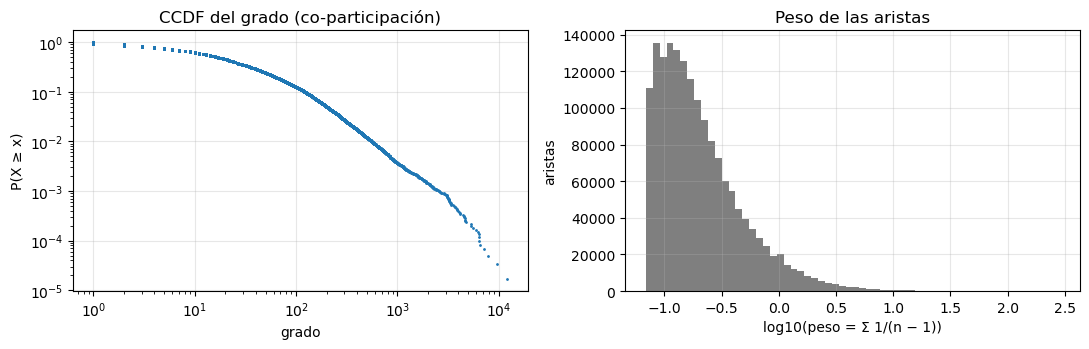

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
x = np.sort(v.grado.to_numpy())
ax[0].loglog(x, 1 - np.arange(len(x)) / len(x), ".", ms=2)
ax[0].set(xlabel="grado", ylabel="P(X ≥ x)", title="CCDF del grado (co-participación)")
ax[1].hist(np.log10(a.peso), bins=60, color="tab:gray")
ax[1].set(xlabel="log10(peso = Σ 1/(n − 1))", ylabel="aristas", title="Peso de las aristas")
mostrar_fig("estructura")

- **60,244 proveedores y 1.64M aristas** (densidad 0.09%): disperso, pero con grado mediano 17, mucho más que el bipartito (1)

- **Cola pesada:** grado p99 = 554 y máximo 12,063

- **763 componentes**, pero la gigante tiene el 96.3% de los nodos: los paseos recorren casi todo el mercado

- Cabe en ~40 MB como CSR: **los paseos y Word2Vec corren en local**

---
### **3. Hubs**

- Un paseo aleatorio ponderado visita cada nodo en proporción a su **fuerza** (Σ pesos): **masa de visita** = fuerza / Σ fuerza

- Si pocos hubs concentran la masa, los paseos pasan por ellos todo el tiempo y "acercan" a proveedores sin relación

- Para cada umbral se retiran los nodos con grado sobre ese percentil y se mide qué se pierde

In [8]:
masa = v.fuerza / v.fuerza.sum()
umbral_hub = []
for pct in RANGO_HUB:
    corte = v.grado.quantile(pct) if pct < 1 else np.inf
    queda = (v.grado <= corte).to_numpy()
    Aq = A[queda][:, queda]
    gq = componente_gigante(Aq)
    fz = np.asarray(Aq.sum(axis=1)).ravel()
    top = np.sort(fz)[::-1][: max(1, int(.01 * queda.sum()))].sum() / fz.sum()
    umbral_hub.append({"percentil": pct, "corte_grado": corte, "hubs_retirados": int((~queda).sum()),
                       "% aristas perdidas": 100 * (1 - Aq.nnz / A.nnz),
                       "% masa de visita retirada": 100 * masa[~queda].sum(),
                       "% nodos en la gigante": 100 * len(gq) / queda.sum(),
                       "masa del top 1% restante": 100 * top})
umbral_hub = pd.DataFrame(umbral_hub).round(2).assign(percentil=RANGO_HUB)
umbral_hub

,percentil,corte_grado,hubs_retirados,% aristas perdidas,% masa de visita retirada,% nodos en la gigante,masa del top 1% restante
0,1.000,inf,0,0.00,0.00,96.28,35.47
1,0.999,2544.28,61,15.53,11.42,94.67,28.74
2,0.995,837.57,302,33.41,24.30,92.62,23.27
3,0.990,554.14,603,43.81,32.22,91.64,20.64


#### a. ¿Quiénes son los hubs?

In [9]:
v["tasa_exito"] = v.n_ganados / v.n_procesos
cols = ["nombre", "grado", "n_procesos", "n_ganados", "tasa_exito", "region", "familia"]
hubs = v.nlargest(TOP_HUBS, "grado")[cols].round(3)
hubs

,nombre,grado,n_procesos,n_ganados,tasa_exito,region,familia
56780,TVT QONTRATISTAS E.I.R.L.,12063,11651,24,0.002,LIMA,7212
45365,INVERSIONES GENERALES LAURA ROCA S.A.C.,9525,8410,2,0.000,LIMA,7212
27386,CRISAMYR SOCIEDAD ANONIMA CERRADA,7861,8940,0,0.000,LIMA,7214
58394,CONSTRUCAPRIGLE E.I.R.L.,7170,6109,12,0.002,LIMA,7212
27201,CORPORACION GRUPO IBIZA S.A.C.,6523,8481,2,0.000,ANCASH,7214
56207,ALLENDE CONTRATISTAS E.I.R.L.,6433,4931,4,0.001,LIMA,7212
58906,OCAMPER S.A.C.,6432,5189,5,0.001,LIMA,7214
53281,INVERSIONES Y EDIFICACIONES JYR S.A.C.,6380,5521,8,0.001,LIMA,2510
50231,CONSTRUCTORA ART PERU E.I.R.L.,6297,4730,0,0.000,LIMA,7214
40995,TECNICAS DE INGENIERIA Y CONTRATOS S.A.C. - TEINGECON S.A.C.,6016,5635,5,0.001,ANCASH,7214


In [10]:
es_hub = v.grado > v.grado.quantile(.999)
pd.DataFrame({"hubs (top 0.1%)": v[es_hub][["n_procesos", "tasa_exito", "n_regiones"]].median(),
              "resto": v[~es_hub][["n_procesos", "tasa_exito", "n_regiones"]].median(),
              }).T.assign(**{"% obras (familias 72xx)": [100 * v[m].familia.fillna("").str.startswith("72").mean() for m in (es_hub, ~es_hub)]}).round(3)

,n_procesos,tasa_exito,n_regiones,% obras (familias 72xx)
hubs (top 0.1%),3887.0,0.001,25.0,70.492
resto,10.0,0.000,2.0,34.857


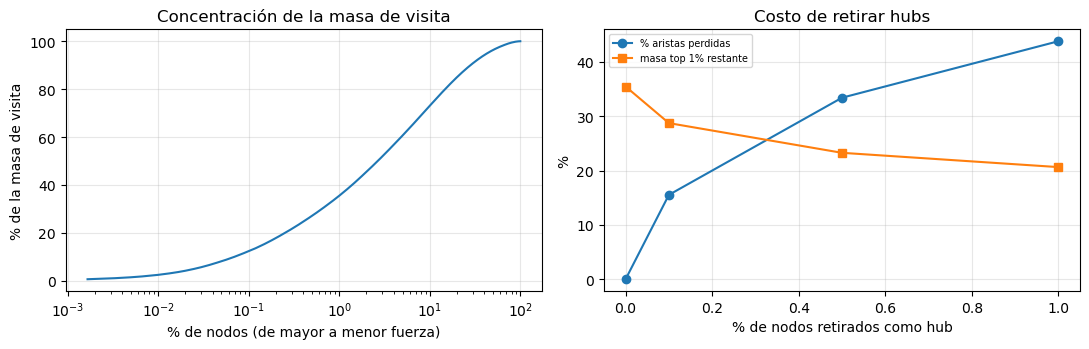

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
orden = np.sort(masa.to_numpy())[::-1]
ax[0].plot(100 * np.arange(1, len(orden) + 1) / len(orden), 100 * np.cumsum(orden))
ax[0].set(xscale="log", xlabel="% de nodos (de mayor a menor fuerza)", ylabel="% de la masa de visita",
          title="Concentración de la masa de visita")
ax[1].plot(100 * (1 - umbral_hub.percentil), umbral_hub["% aristas perdidas"], "o-", label="% aristas perdidas")
ax[1].plot(100 * (1 - umbral_hub.percentil), umbral_hub["masa del top 1% restante"], "s-", label="masa top 1% restante")
ax[1].set(xlabel="% de nodos retirados como hub", ylabel="%", title="Costo de retirar hubs"); ax[1].legend(fontsize=7)
mostrar_fig("hubs")

- **Los hubs no son grandes proveedores: son postores masivos.** TVT Qontratistas participó en 11,651 procesos y ganó 24; Crisamyr ofertó en 8,940 y no ganó ninguno

- Casi todos son de **obras** (familias 7212, 7214) en Lima y Áncash: ofertan a todo lo que se convoca en su rubro

- Sus aristas miden **volumen de oferta, no afinidad**: coincidir con un postor masivo en 2 procesos no dice nada del otro proveedor

- **Masa de visita:** sin retirar a nadie, el 1% de nodos con más fuerza se lleva el **35.5%** de los pasos de un paseo

- **Retirar el top 0.1% (61 nodos)** quita 11.4% de la masa y 15.5% de las aristas, y la gigante conserva el 94.7% de los nodos

- Pasar a 0.5% o 1% retira 300-600 nodos y un tercio o más de las aristas: ya se pierde estructura real del mercado

- Se fija `PCT_HUB = 0.999`: solo los postores masivos extremos; quedan como **hallazgo descriptivo** (patrón de oferta), no como sospecha

In [12]:
PCT_HUB = 0.999

#### a. Subgrafo final

- Se quitan los hubs según `PCT_HUB` y se conserva la componente gigante: Node2Vec necesita que todo nodo tenga vecinos

In [13]:
corte = v.grado.quantile(PCT_HUB) if PCT_HUB < 1 else np.inf
queda = np.flatnonzero((v.grado <= corte).to_numpy())
g = queda[componente_gigante(A[queda][:, queda])]
nodos = v.iloc[g].reset_index(drop=True).rename(columns={"idx": "idx_artefacto"})
nodos["idx"] = np.arange(len(nodos))
mapa = np.full(len(v), -1); mapa[g] = nodos.idx
ar = a.assign(i=mapa[a.i], j=mapa[a.j]).query("i >= 0 and j >= 0")[["i", "j", "peso", "n_coparticipa"]]
print(f"subgrafo: {len(nodos):,} nodos ({100 * len(nodos) / len(v):.1f}%) | {len(ar):,} aristas ({100 * len(ar) / len(a):.1f}%)")

subgrafo: 56,975 nodos (94.6%) | 1,383,731 aristas (84.3%)


---
### **4. Co-participación por año**

- **Para predecir enlaces sin fuga** hace falta saber **cuándo** aparece cada arista

- Mismas reglas que `01_Trans/c_uso`: procesos de 2 a `MAX_PART` participantes, `repartition(ocid)` + `cache` antes del self-join

- Una arista del año = par que coincidió en **≥ `MIN_COMP` procesos ese año**

In [14]:
SHUFFLE = int(spark.conf.get("spark.sql.shuffle.partitions"))
p_anio = part.select("ocid", "proveedor_key").join(F.broadcast(procesos.select("ocid", "anio")), "ocid")
n_part = p_anio.groupBy("ocid").agg(F.count("*").alias("n"))
p_n = p_anio.join(n_part.where(f"n BETWEEN 2 AND {MAX_PART}"), "ocid").repartition(SHUFFLE, "ocid").cache()
pares_anio = (p_n.alias("a").join(p_n.alias("b"), (F.col("a.ocid") == F.col("b.ocid")) &
                                  (F.col("a.proveedor_key") < F.col("b.proveedor_key")))
              .select(F.col("a.proveedor_key").alias("src"), F.col("b.proveedor_key").alias("dst"), F.col("a.anio").alias("anio"),
                      F.col("a.n").alias("n"))
              .groupBy("src", "dst", "anio").agg(F.count("*").alias("n_coparticipa"), F.sum(1.0 / (F.col("n") - 1)).alias("peso"))
              .where(f"n_coparticipa >= {MIN_COMP}"))
aristas_anio = pares_anio.toPandas()
p_n.unpersist()
pos = pd.Series(nodos.idx.to_numpy(), index=nodos.clave)
aristas_anio = aristas_anio.assign(i=aristas_anio.src.map(pos), j=aristas_anio.dst.map(pos)).dropna(subset=["i", "j"])
aristas_anio = aristas_anio.astype({"i": int, "j": int})[["i", "j", "anio", "n_coparticipa", "peso"]]
extremos = pd.concat([aristas_anio[["anio", "i"]], aristas_anio[["anio", "j"]].rename(columns={"j": "i"})])
por_anio = (aristas_anio.groupby("anio").size().rename("aristas").to_frame()
            .join(extremos.groupby("anio").i.nunique().rename("nodos_activos")).reset_index())
por_anio

,anio,aristas,nodos_activos
0,2023,482865,30632
1,2024,490300,30983
2,2025,508987,31700


- Cada año tiene **~480-510k aristas** entre ~31k proveedores activos (los que co-participaron ≥ 2 veces ese año)

In [15]:
llave = lambda d: set(zip(d.i, d.j))
e = {y: llave(aristas_anio[aristas_anio.anio == y]) for y in anios}
nuevos = pd.DataFrame([
    ("2024 nuevas respecto de 2023", len(e[2024] - e[2023]), 100 * len(e[2024] - e[2023]) / len(e[2024])),
    ("2025 nuevas respecto de 2023-2024", len(e[2025] - e[2023] - e[2024]), 100 * len(e[2025] - e[2023] - e[2024]) / len(e[2025])),
    ("se repiten en los tres años", len(e[2023] & e[2024] & e[2025]), np.nan)], columns=["medida", "pares", "% del año"]).round(1)
nuevos

,medida,pares,% del año
0,2024 nuevas respecto de 2023,384343,78.4
1,2025 nuevas respecto de 2023-2024,373565,73.4
2,se repiten en los tres años,49112,NaN


- **El 78% de las aristas de 2024 y el 73% de las de 2025 son nuevas:** el mercado de co-participación se renueva mucho de un año a otro

- Solo **49k pares** compiten juntos en los tres años: el núcleo estable de competidores recurrentes

- Hay **~380k pares nuevos por año** para evaluar: predecir quién empezará a competir con quién es una tarea **difícil y con mucha señal**

---
### **5. Exportación a `temp/datos/`**

- `nodos.parquet`: idx, clave, nombre, consorcio, grado, fuerza, región, familia, segmento y actividad

- `aristas.parquet`: subgrafo final (i < j) con `peso` y `n_coparticipa`

- `aristas_anio.parquet`: co-participación por año entre nodos del subgrafo

In [16]:
nodos[["idx", "clave", "nombre", "es_consorcio", "grado", "fuerza", "region", "familia", "segmento", "n_procesos",
       "n_ganados", "n_regiones"]].to_parquet(datos_dir / "nodos.parquet", index=False)
ar.to_parquet(datos_dir / "aristas.parquet", index=False)
aristas_anio.to_parquet(datos_dir / "aristas_anio.parquet", index=False)
config = leer_config()
config.update({"pct_hub": PCT_HUB, "n_nodos": len(nodos), "n_aristas": len(ar)})
guardar_config(config)

#### a. Verificación

Índices contiguos, aristas dentro del subgrafo y un solo componente

In [17]:
nd, ad = pd.read_parquet(datos_dir / "nodos.parquet"), pd.read_parquet(datos_dir / "aristas.parquet")
assert (nd.idx.to_numpy() == np.arange(len(nd))).all()
assert ad[["i", "j"]].max().max() < len(nd) and (ad.i < ad.j).all()
assert connected_components(matriz_adyacencia(ad.i, ad.j, ad.peso, len(nd)), directed=False)[0] == 1
print(f"OK: {len(nd):,} nodos, {len(ad):,} aristas, {len(aristas_anio):,} aristas por año")

OK: 56,975 nodos, 1,383,731 aristas, 1,482,152 aristas por año


---
### **6. Escritura de resultados**

In [18]:
escritos = guardar_tablas({"estructura": estructura.astype({"valor": float}), "umbral_hub": umbral_hub,
                           "hubs": hubs.fillna("sin dato"), "por_anio": por_anio, "nuevos_por_anio": nuevos.fillna(0)})

Escrito en 06_Embeddings/temp/a_grafo/: estructura, umbral_hub, hubs, por_anio, nuevos_por_anio


#### a. Verificación

In [19]:
verificar_salidas(escritos)

OK: 5 tablas (parquet + json) | 2 figuras: estructura, hubs


---
### **7. Cerrar sesión**

In [20]:
spark.stop()